
========== BASELINE NO_SEGMENTATION ==========
              precision    recall  f1-score   support

           0       0.87      0.89      0.88      1409
           1       0.28      0.50      0.36       167
           2       0.96      0.87      0.91      1590

    accuracy                           0.86      3166
   macro avg       0.70      0.75      0.72      3166
weighted avg       0.88      0.86      0.87      3166



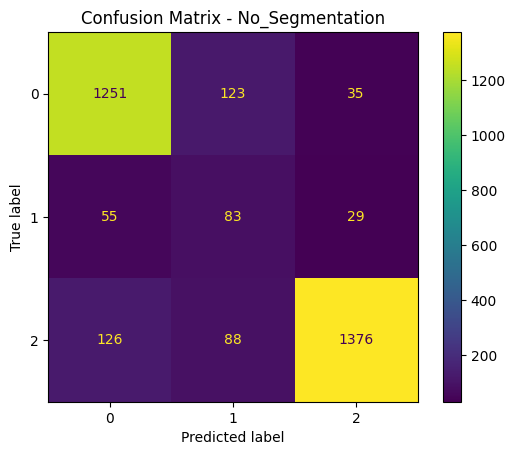


========== BASELINE UNDERTHESEA ==========
              precision    recall  f1-score   support

           0       0.82      0.85      0.84      1409
           1       0.18      0.63      0.28       167
           2       0.96      0.68      0.79      1590

    accuracy                           0.75      3166
   macro avg       0.65      0.72      0.64      3166
weighted avg       0.86      0.75      0.79      3166



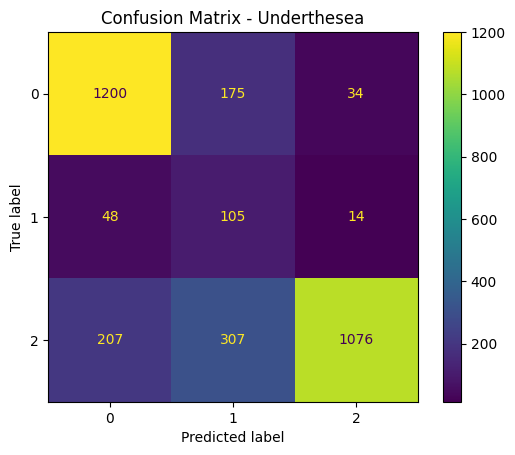


========== BASELINE VNCORENLP ==========
              precision    recall  f1-score   support

           0       0.87      0.89      0.88      1409
           1       0.28      0.50      0.36       167
           2       0.96      0.87      0.91      1590

    accuracy                           0.86      3166
   macro avg       0.70      0.75      0.72      3166
weighted avg       0.88      0.86      0.87      3166



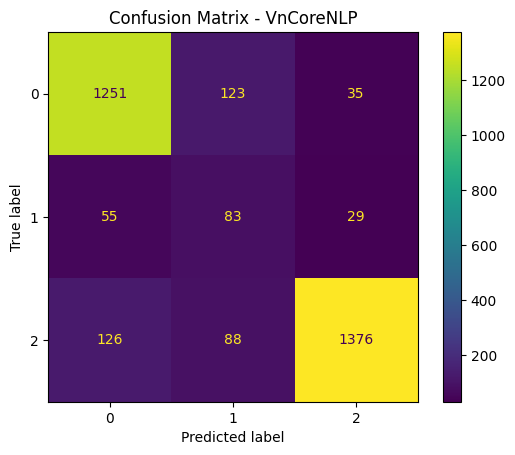

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from underthesea import word_tokenize
import py_vncorenlp


# 1. TẢI DỮ LIỆU
train_df = pd.read_csv("../data/processed/train_cleaned.csv").dropna()
test_df = pd.read_csv("../data/raw/test.csv").dropna()

# 2. ĐỊNH NGHĨA 3 PHƯƠNG PHÁP TÁCH TỪ
def no_segmentation(text):
    return text

def underthesea_segmentation(text):
    return word_tokenize(text, format="text")

# Khởi tạo VnCoreNLP (giả sử đã tải model về thư mục ./VnCoreNLP)
try:
    rdrsegmenter = py_vncorenlp.VnCoreNLP(annotators="wseg", save_dir='./VnCoreNLP')
except:
    rdrsegmenter = None

def vncorenlp_segmentation(text):
    if rdrsegmenter is None: return text
    sentences = rdrsegmenter.annotate_text(text)
    words = [word['form'] for sentence in sentences for word in sentence]
    return " ".join(words)

# 3. HÀM ĐÁNH GIÁ VÀ VẼ BIỂU ĐỒ (Đã tích hợp Confusion Matrix)
def evaluate_method(segmentation_func, method_name, model):
    print(f"\n{'='*10} BASELINE {method_name.upper()} {'='*10}")
    
    # Tiền xử lý dữ liệu
    X_train_seg = train_df['tokenized'] # Giả sử 'tokenized' đã có sẵn hoặc bạn dùng cột comment
    X_test_seg = test_df['comment'].apply(segmentation_func)
    
    # Vector hóa
    tfidf = TfidfVectorizer(ngram_range=(1, 2), max_features=5000)
    X_train_vec = tfidf.fit_transform(X_train_seg)
    X_test_vec = tfidf.transform(X_test_seg)
    
    # Huấn luyện
    model.fit(X_train_vec, train_df['label'])
    
    # Dự đoán
    y_pred = model.predict(X_test_vec)
    
    # In báo cáo
    print(classification_report(test_df['label'], y_pred))
    
    # Vẽ và lưu Confusion Matrix
    ConfusionMatrixDisplay.from_predictions(test_df['label'], y_pred)
    plt.title(f"Confusion Matrix - {method_name}")
    
    # Lưu file (cần đảm bảo thư mục ../results đã tồn tại)
    plt.savefig(f'../results/Confusion_Matrix_{method_name}.png')
    plt.show()

# 4. CHẠY THỬ NGHIỆM
# Khởi tạo mô hình dùng chung (ví dụ Logistic Regression như code bạn cung cấp)
model = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)

# Lần lượt chạy 3 phương pháp
evaluate_method(no_segmentation, "No_Segmentation", model)
evaluate_method(underthesea_segmentation, "Underthesea", model)
evaluate_method(vncorenlp_segmentation, "VnCoreNLP", model)

In [4]:
import os
os.environ['HF_HUB_DISABLE_SYMLINKS'] = '1'
from transformers import AutoTokenizer

# Khởi tạo tokenizer 
tokenizer = AutoTokenizer.from_pretrained("vinai/phobert-base")
import pandas as pd
import torch
from torch.utils.data import Dataset

df = pd.read_csv('../data/processed/train_cleaned.csv') 

# 2. Định nghĩa một Dataset class 
class TextDataset(Dataset):
    def __init__(self, texts, tokenizer, max_length=256):
        self.texts = texts
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        text = str(self.texts[idx])
        inputs = self.tokenizer(
            text, 
            padding='max_length', 
            truncation=True, 
            max_length=self.max_length, 
            return_tensors="pt"
        )
        return {
            'input_ids': inputs['input_ids'].squeeze(0),
            'attention_mask': inputs['attention_mask'].squeeze(0)
        }

dataset = TextDataset(df['tokenized'].values, tokenizer)

sample = dataset[0]
print(sample['input_ids'])

tensor([    0, 48090,  4368,  1893,   545,   312,     2,     1,     1,     1,
            1,     1,     1,     1,     1,     1,     1,     1,     1,     1,
            1,     1,     1,     1,     1,     1,     1,     1,     1,     1,
            1,     1,     1,     1,     1,     1,     1,     1,     1,     1,
            1,     1,     1,     1,     1,     1,     1,     1,     1,     1,
            1,     1,     1,     1,     1,     1,     1,     1,     1,     1,
            1,     1,     1,     1,     1,     1,     1,     1,     1,     1,
            1,     1,     1,     1,     1,     1,     1,     1,     1,     1,
            1,     1,     1,     1,     1,     1,     1,     1,     1,     1,
            1,     1,     1,     1,     1,     1,     1,     1,     1,     1,
            1,     1,     1,     1,     1,     1,     1,     1,     1,     1,
            1,     1,     1,     1,     1,     1,     1,     1,     1,     1,
            1,     1,     1,     1,     1,     1,     1,     1, 